# Analysis of Bakery Sales During Kiel Week

## Hypothesis

Average daily bakery sales are higher during Kiel Week
than during comparable days outside the festival period.

## Objective

The objective of this analysis is to investigate whether
average daily bakery sales increase during Kiel Week
compared with similar days outside the festival period.

We will use descriptive statistics and visualizations
to compare the two periods.


The notebook follows the four points from the instructions, focused on the data used for this hypothesis (sales and Kiel Week dates):

1. Dataset overview
2. Missing values
3. Feature distributions
4. Correlations: Kiel Week and sales

## 1. Dataset overview

We load two files from the course repository: the daily sales per product group (`umsatzdaten_gekuerzt.csv`) and the list of Kiel Week days (`kiwo.csv`). We combine them into one table `df`, with a column `KielerWoche` that is 1 on Kiel Week days and 0 on all other days.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
sales = pd.read_csv(base + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
kiwo = pd.read_csv(base + "kiwo.csv", parse_dates=["Datum"])

# Left join: keep every sales row; days not in kiwo.csv are not Kiel Week -> 0
df = sales.merge(kiwo, on="Datum", how="left")
df["KielerWoche"] = df["KielerWoche"].fillna(0).astype(int)

# Product names from the dataset documentation, and chart colours used throughout
names = {1: "Bread", 2: "Bread rolls", 3: "Croissant", 4: "Pastries", 5: "Cake", 6: "Seasonal bread"}
BLUE, ORANGE = "#2a78d6", "#eb6834"

df.head()

,id,Datum,Warengruppe,Umsatz,KielerWoche
0,1307011,2013-07-01,1,148.828353,0
1,1307021,2013-07-02,1,159.793757,0
2,1307031,2013-07-03,1,111.885594,0
3,1307041,2013-07-04,1,168.864941,0
4,1307051,2013-07-05,1,171.280754,0


In [11]:
# Overview: size, column types, time period, product groups, Kiel Weeks covered
print("Sales file:", sales.shape[0], "rows,", sales.shape[1], "columns")
print("Kiel Week file:", kiwo.shape[0], "rows,", kiwo.shape[1], "columns")
print()
print(sales.dtypes)
print()
print("Period:", sales["Datum"].min().date(), "to", sales["Datum"].max().date())
print("Number of different days with sales:", sales["Datum"].nunique())

kiel_in_period = kiwo[kiwo["Datum"].between(sales["Datum"].min(), sales["Datum"].max())]
print("Kiel Week days within the sales period:", len(kiel_in_period),
      "| years:", sorted(kiel_in_period["Datum"].dt.year.unique().tolist()))

# Rows per product group (one row = one product group on one day)
sales["Warengruppe"].value_counts().sort_index().rename(index=names).rename("rows")

Sales file: 9334 rows, 4 columns
Kiel Week file: 72 rows, 2 columns

id                      int64
Datum          datetime64[us]
Warengruppe             int64
Umsatz                float64
dtype: object

Period: 2013-07-01 to 2018-07-31
Number of different days with sales: 1819
Kiel Week days within the sales period: 45 | years: [2014, 2015, 2016, 2017, 2018]


Warengruppe
Bread             1819
Bread rolls       1819
Croissant         1819
Pastries          1766
Cake              1819
Seasonal bread     292
Name: rows, dtype: int64

In [12]:
print(len(df))                           # should be 9334
print(df["KielerWoche"].value_counts())  # only 0s and 1s


9334
KielerWoche
0    9111
1     223
Name: count, dtype: int64


**What the overview shows:** the sales data covers 1 July 2013 to 31 July 2018, with one row per product group and day (6 product groups). Kiel Week lasts 9 days each June. 5 Kiel Weeks (2014–2018, 45 days) fall within the sales period; the 2013 Kiel Week was before the data starts. After combining the files, the table still has 9334 rows, so no rows were lost or duplicated.

## 2. Missing values

We check two things: empty cells in the data, and **days that are missing completely** (a day with no row in the sales file).

In [13]:
# 1) Empty cells in the sales file
print("Empty cells per column:")
print(sales.isna().sum())
print()

# 2) Missing days: compare the calendar with the days that have sales
all_days = pd.date_range(sales["Datum"].min(), sales["Datum"].max())
days_without_sales = all_days.difference(sales["Datum"].unique())
print("Calendar days:", len(all_days), "| days with sales:", sales["Datum"].nunique(),
      "| days without any sales:", len(days_without_sales))
print(list(days_without_sales.strftime("%Y-%m-%d")))
print()

# Are any product groups missing on Kiel Week days?
kiel_days = kiwo[kiwo["Datum"].between(sales["Datum"].min(), sales["Datum"].max())]["Datum"]
for g in [1, 2, 3, 4, 5]:
    missing = kiel_days[~kiel_days.isin(sales[sales["Warengruppe"] == g]["Datum"])]
    print(f"{names[g]}: missing on {len(missing)} Kiel Week days", list(missing.dt.strftime("%Y-%m-%d")))
print()

# 3) Missing days per product group
coverage = pd.DataFrame({"days with sales": sales.groupby("Warengruppe")["Datum"].nunique()})
coverage["days missing"] = len(all_days) - coverage["days with sales"]
coverage.rename(index=names)

Empty cells per column:
id             0
Datum          0
Warengruppe    0
Umsatz         0
dtype: int64

Calendar days: 1857 | days with sales: 1819 | days without any sales: 38
['2013-12-25', '2013-12-26', '2013-12-28', '2014-01-01', '2014-04-18', '2014-05-01', '2014-05-03', '2014-05-04', '2014-08-17', '2014-12-25', '2014-12-26', '2015-01-01', '2015-04-03', '2015-05-01', '2015-12-25', '2015-12-26', '2016-01-01', '2016-03-24', '2016-03-25', '2016-07-07', '2016-07-18', '2016-08-14', '2016-08-15', '2016-12-17', '2016-12-25', '2016-12-26', '2017-01-01', '2017-04-14', '2017-05-01', '2017-07-04', '2017-10-23', '2017-10-31', '2017-12-25', '2017-12-26', '2018-01-01', '2018-03-30', '2018-05-01', '2018-05-21']

Bread: missing on 0 Kiel Week days []
Bread rolls: missing on 0 Kiel Week days []
Croissant: missing on 0 Kiel Week days []
Pastries: missing on 2 Kiel Week days ['2015-06-20', '2016-06-24']
Cake: missing on 0 Kiel Week days []



,days with sales,days missing
Warengruppe,,
Bread,1819,38
Bread rolls,1819,38
Croissant,1819,38
Pastries,1766,91
Cake,1819,38
Seasonal bread,292,1565


**What the missing-value check shows:**

- The sales file has **no empty cells**.
- But some **days are missing entirely**: on 38 days there are no sales at all. These are mostly public holidays (Christmas, New Year, Easter, 1 May), when the bakery is presumably closed. None of them falls in a Kiel Week.
- **Pastries** are missing on 91 days, so on some extra days no pastries were recorded. Two of these are Kiel Week days (20 June 2015 and 24 June 2016). That is why the combined table has 223 Kiel Week rows instead of 45 days × 5 groups = 225. Pastries are therefore compared on 43 instead of 45 Kiel Week days, which is a small effect.
- **Seasonal bread** only appears on 292 days, from October to January. It is a winter product, which is why it has no Kiel Week values.
- The `KielerWoche` column was empty for all non-Kiel-Week days after combining the files. We filled these with 0 on purpose (0 = not Kiel Week), so it has no missing values.

## 3. Feature distributions

How are daily sales spread out? We look at summary statistics per product group, and at a **box plot** comparing Kiel Week days with other summer days. In a box plot, the box shows the middle 50 % of days, the white line is the median (the typical day), the whiskers show the normal range, and the dots are unusually high or low days.

,count,mean,std,min,25%,50%,75%,max
Warengruppe,,,,,,,,
Bread,1819.0,122.1,40.3,23.1,96.4,120.1,144.3,416.8
Bread rolls,1819.0,402.5,139.7,175.0,289.1,370.8,492.8,1203.4
Croissant,1819.0,163.3,75.6,37.7,105.6,142.8,202.0,565.9
Pastries,1766.0,88.0,35.3,27.4,66.0,80.0,98.3,430.5
Cake,1819.0,276.8,99.5,121.5,229.0,266.0,307.6,1879.5
Seasonal bread,292.0,66.9,32.4,7.1,41.6,62.9,86.2,172.9


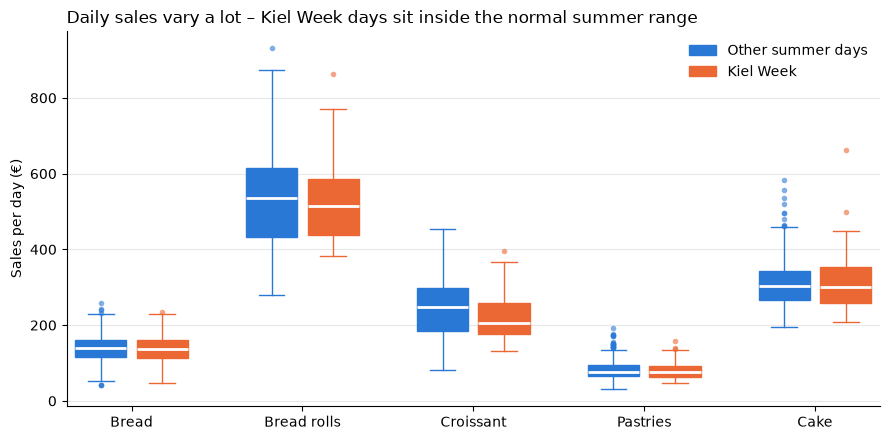

In [14]:
# Summary statistics of daily sales per product group
display(df.groupby("Warengruppe")["Umsatz"].describe().round(1).rename(index=names))

# Box plot: daily sales on Kiel Week days vs other summer days (June–August)
summer = df[df["Datum"].dt.month.isin([6, 7, 8])]
groups = [1, 2, 3, 4, 5]                   # seasonal bread is not sold in summer
pos_other = np.arange(len(groups)) * 2.5
pos_kiel = pos_other + 0.9

fig, ax = plt.subplots(figsize=(9, 4.5))
for kw, pos, colour, label in [(0, pos_other, BLUE, "Other summer days"),
                               (1, pos_kiel, ORANGE, "Kiel Week")]:
    data = [summer[(summer["Warengruppe"] == g) & (summer["KielerWoche"] == kw)]["Umsatz"] for g in groups]
    bp = ax.boxplot(data, positions=pos, widths=0.75, patch_artist=True,
                    medianprops=dict(color="white", linewidth=2),
                    flierprops=dict(marker="o", markersize=4, markerfacecolor=colour, markeredgecolor="none", alpha=0.6),
                    whiskerprops=dict(color=colour), capprops=dict(color=colour),
                    boxprops=dict(facecolor=colour, edgecolor=colour))
    bp["boxes"][0].set_label(label)
ax.set_xticks(pos_other + 0.45, [names[g] for g in groups])
ax.set_ylabel("Sales per day (€)")
ax.set_title("Daily sales vary a lot – Kiel Week days sit inside the normal summer range", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**What the distributions show:**

- Sales differ a lot between product groups: bread rolls sell by far the most (median about 370 € per day), pastries and seasonal bread the least.
- Daily sales vary strongly within each group, and there are some unusually high days (for example cake up to about 1880 €).
- In the box plot, the Kiel Week boxes (orange) lie within the range of normal summer days (blue). Kiel Week days are not unusual compared with other summer days.

## 4. Correlations: Kiel Week and sales

Kiel Week is a yes/no variable, so instead of a single correlation number we compare **average sales on Kiel Week days with average sales on other days**, per product group. We do this twice: first against all other days, then only against other summer days (June–August), because Kiel Week always takes place in summer.

In [15]:
# Average sales per product group: normal days (0) vs Kiel Week (1)
comparison = df.groupby(["Warengruppe", "KielerWoche"])["Umsatz"].mean().unstack()
comparison.columns = ["Normal days", "Kiel Week"]
comparison["Difference (%)"] = (comparison["Kiel Week"] / comparison["Normal days"] - 1) * 100
comparison.round(1)


,Normal days,Kiel Week,Difference (%)
Warengruppe,,,
1,121.8,136.0,11.7
2,399.0,538.6,35.0
3,161.8,223.3,38.0
4,88.1,81.2,-7.9
5,275.8,315.7,14.5
6,66.9,NaN,NaN


In [16]:
# Compare Kiel Week only with other summer days (June–August)
summer = df[df["Datum"].dt.month.isin([6, 7, 8])]

summer_comparison = summer.groupby(["Warengruppe", "KielerWoche"])["Umsatz"].mean().unstack()
summer_comparison.columns = ["Other summer days", "Kiel Week"]
summer_comparison["Difference (%)"] = (summer_comparison["Kiel Week"] / summer_comparison["Other summer days"] - 1) * 100
summer_comparison.round(1)


,Other summer days,Kiel Week,Difference (%)
Warengruppe,,,
1,138.8,136.0,-2.0
2,532.9,538.6,1.1
3,244.6,223.3,-8.7
4,82.3,81.2,-1.4
5,310.6,315.7,1.6


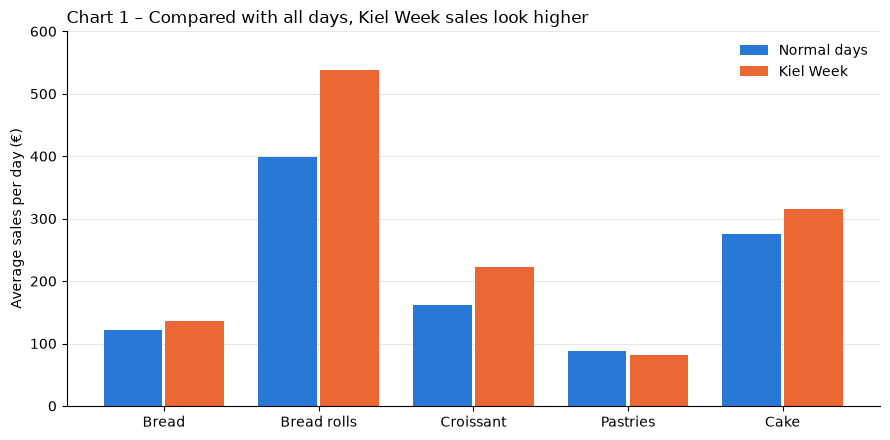

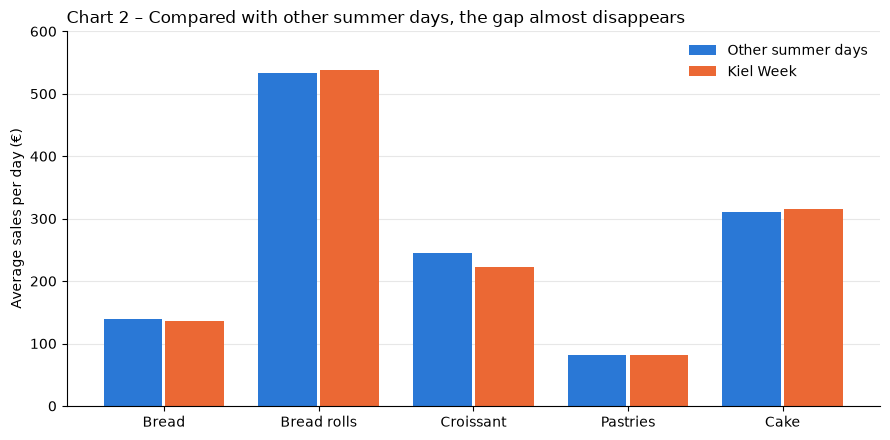

In [17]:
def grouped_bars(table, col_a, col_b, title):
    t = table[[col_a, col_b]].dropna()          # drops group 6 (no Kiel Week sales)
    x = np.arange(len(t))
    w = 0.38
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(x - w/2 - 0.01, t[col_a], w, color=BLUE, label=col_a)
    ax.bar(x + w/2 + 0.01, t[col_b], w, color=ORANGE, label=col_b)
    ax.set_xticks(x, [names[g] for g in t.index])
    ax.set_ylabel("Average sales per day (€)")
    ax.set_title(title, loc="left", fontsize=12)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_ylim(0, 600)                        # same scale in chart 1 and 2
    plt.tight_layout()
    plt.show()

# Chart 1: Kiel Week vs ALL other days
grouped_bars(comparison, "Normal days", "Kiel Week",
             "Chart 1 – Compared with all days, Kiel Week sales look higher")

# Chart 2: Kiel Week vs other SUMMER days (June–August)
grouped_bars(summer_comparison, "Other summer days", "Kiel Week",
             "Chart 2 – Compared with other summer days, the gap almost disappears")

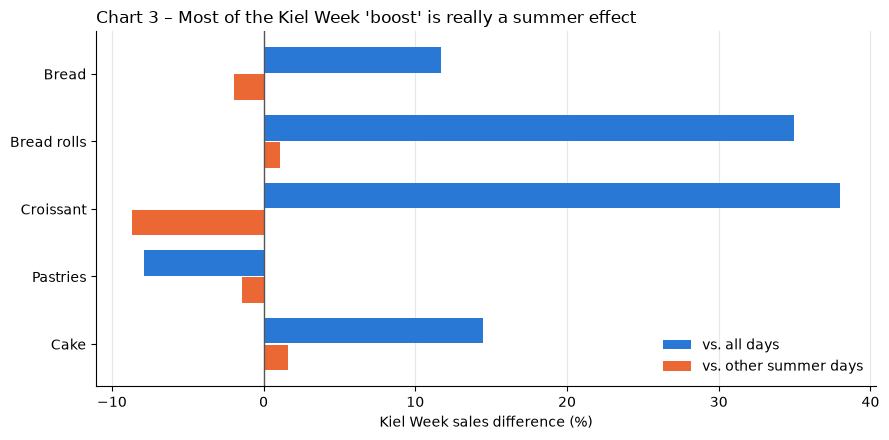

In [18]:
# Chart 3: the % difference from both comparisons side by side
diff = pd.DataFrame({
    "vs. all days": comparison["Difference (%)"],
    "vs. other summer days": summer_comparison["Difference (%)"],
}).dropna()
y = np.arange(len(diff))
h = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(y - h/2 - 0.01, diff["vs. all days"], h, color=BLUE, label="vs. all days")
ax.barh(y + h/2 + 0.01, diff["vs. other summer days"], h, color=ORANGE, label="vs. other summer days")
ax.axvline(0, color="#555555", linewidth=1)
ax.set_yticks(y, [names[g] for g in diff.index])
ax.invert_yaxis()
ax.set_xlabel("Kiel Week sales difference (%)")
ax.set_title("Chart 3 – Most of the Kiel Week 'boost' is really a summer effect", loc="left", fontsize=12)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

,Other summer days,Kiel Week,Difference (%)
Year,,,
2013,290.7,NaN,NaN
2014,271.4,248.3,-8.5
2015,225.9,204.0,-9.7
2016,219.6,196.4,-10.5
2017,224.3,234.0,4.3
2018,247.4,233.9,-5.5


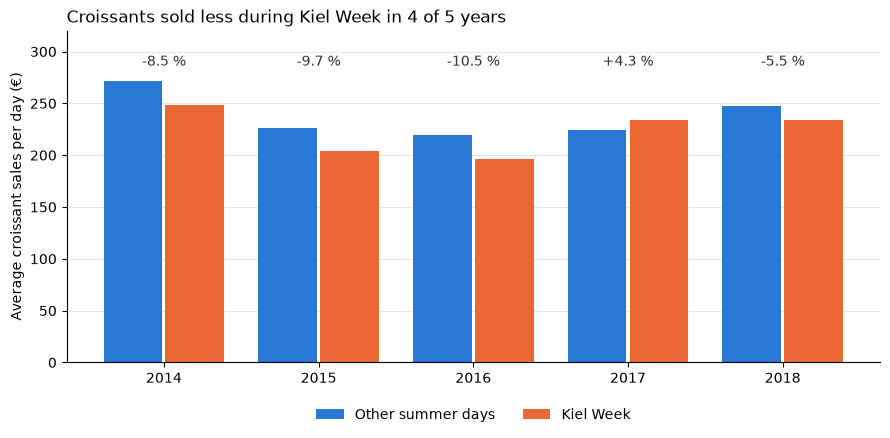

In [19]:
# Croissants (group 3): is the Kiel Week dip consistent across years?
cro = summer[summer["Warengruppe"] == 3].copy()
cro["Year"] = cro["Datum"].dt.year

per_year = cro.groupby(["Year", "KielerWoche"])["Umsatz"].mean().unstack()
per_year.columns = ["Other summer days", "Kiel Week"]
per_year["Difference (%)"] = (per_year["Kiel Week"] / per_year["Other summer days"] - 1) * 100
display(per_year.round(1))

# Chart: one pair of bars per year, with the % difference written above
t = per_year.dropna()                      # 2013 has no Kiel Week in the data
x = np.arange(len(t))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w/2 - 0.01, t["Other summer days"], w, color=BLUE, label="Other summer days")
ax.bar(x + w/2 + 0.01, t["Kiel Week"], w, color=ORANGE, label="Kiel Week")
for xi, d in zip(x, t["Difference (%)"]):
    ax.text(xi, t["Other summer days"].max() + 15, f"{d:+.1f} %", ha="center", fontsize=10, color="#333333")
ax.set_xticks(x, t.index)
ax.set_ylabel("Average croissant sales per day (€)")
ax.set_title("Croissants sold less during Kiel Week in 4 of 5 years", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, 320)
plt.tight_layout()
plt.show()

In [20]:
# Is the croissant difference bigger than normal day-to-day variation?
# Mann–Whitney U test: compares Kiel Week days with other summer days
from scipy import stats

kiel = cro[cro["KielerWoche"] == 1]["Umsatz"]
other = cro[cro["KielerWoche"] == 0]["Umsatz"]
result = stats.mannwhitneyu(kiel, other)
print(f"Kiel Week days: {len(kiel)}, other summer days: {len(other)}")
print(f"p-value: {result.pvalue:.3f}")

Kiel Week days: 45, other summer days: 440
p-value: 0.051


## Conclusion

**The hypothesis is not supported.** Kiel Week does not noticeably increase bakery sales once we compare it with other summer days.

### What we found

- **Compared with all days of the year, Kiel Week looks like a big boost:** bread rolls +35 %, croissants +38 %, cake +15 %, bread +12 % (pastries −8 %). See Chart 1.
- **Compared with other summer days (June–August), the boost almost disappears:** differences are between −9 % and +2 % for all product groups. See Chart 2.
- **The first result was mainly a summer effect** (see Chart 3). Kiel Week always takes place in late June, when sales are higher anyway. Summer is a *confounder*: it affects both "is it Kiel Week?" and sales, which made Kiel Week look more important than it is.

### A possible pattern: croissants

Croissants are the only group with a noticeable difference: during Kiel Week they sold about 9 % less than on other summer days. This happened in 4 of the 5 years (2014–2016 and 2018), but not in 2017 (+4 %). A statistical test (Mann–Whitney U) gave p ≈ 0.05, which is borderline. Two reasons for caution:

- We compared five product groups, so one of them standing out by chance is not unusual.
- Kiel Week is in late June, while July and August are the main holiday months; the dip may partly reflect that, rather than Kiel Week itself.

We treat this as a possible pattern to discuss with the team, not as a confirmed effect.

### Limits of this analysis

- **Data period:** 1 July 2013 – 31 July 2018. This includes 5 Kiel Weeks (2014–2018), 45 days in total (43 for pastries, which are missing on 2 Kiel Week days), which is a small sample.
- **Seasonal bread (group 6)** is not sold in summer, so it could not be compared.
- We compared averages only. We did not account for other factors such as weekday, weather or holidays.

### What this means for the forecast

Season or month looks much more important for predicting sales than Kiel Week. Kiel Week on its own is probably a weak input for the model. Whether to include it, and whether to look further into the croissant pattern, is for the team to decide.